In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import scipy
import splines
import pyclipr
import os
from tqdm import tqdm

In [63]:
MODELS = os.listdir("results/trajectories")
trajectories = [torch.load(f"results/trajectories/{model}", weights_only=False) for model in tqdm(MODELS)]

100%|██████████| 185/185 [00:01<00:00, 113.84it/s]


In [64]:
trajectories[2]["agents", "done"].sum()

tensor(0)

In [ ]:
L = torch.max(torch.stack([traj["agents", "progress_abs"] for traj in trajectories]))

def first_lap_slice(traj, L):
    p = traj["agents", "progress_abs"].reshape(-1)
    T = p.shape[0]

    dp = p[1:] - p[:-1]
    cross = (dp < -L/2).long() - (dp > L/2).long()      # [T-1]
    c0 = -1 if p[0] > L/2 else 0
    c = c0 + torch.cat([cross.new_zeros(1), cross.cumsum(0)])  # [T]; c[t] = net crossings up to frame t

    fin = torch.where(c >= 1)[0]
    finish_t = int(fin[0]) if len(fin) else T - 1

    done = traj["next", "agents", "done"].reshape(-1)             # or "terminated" for crashes only
    d = torch.where(done)[0]
    done_t = int(d[0]) if len(d) else T - 1

    end = min(finish_t, done_t)
    reason = "finished" if finish_t <= done_t and len(fin) else ("done" if len(d) else "ran_out")
    return traj[: end + 1], reason


first_laps = []
for traj in trajectories:
    first_laps.append(first_lap_slice(traj, L))


stats = pd.DataFrame({
    "model": MODELS,
    "lap_time": [lap[0].shape[0]/25.0 for lap in first_laps],
    "reason": [lap[1] for lap in first_laps]
})
stats[stats["reason"] == "finished"]
stats["iteration"] = stats["model"].str[-8:-3]
stats["model_category"] = stats["model"].str.split("_").str[:-3].str.join("_")
stats["aux_weight"] = stats["model"].str.split("_").str[-3]
stats["seed"] = stats["model"].str.split("_").str[-2]
stats["model_category"].value_counts()

model_category
curvature_close        90
rnn_curvature_close    45
baseline               35
rnn_baseline           15
Name: count, dtype: int64

In [72]:
stats[["model_category", "aux_weight"]].value_counts()

model_category       aux_weight
baseline             w0            35
curvature_close      w0.1          30
                     w0.3          30
                     w1            30
rnn_baseline         w0            15
rnn_curvature_close  w0.1          15
                     w0.3          15
                     w1            15
Name: count, dtype: int64

In [106]:
stats

,model,lap_time,reason,iteration,model_category,aux_weight,seed,arch,w,finished,lap_time_fin,progress
0,rnn_curvature_close_w0.3_s1_00590.pt,39.92,finished,00590,rnn_curvature_close,w0.3,s1,RNN,0.3,True,39.92,1.000000
1,rnn_curvature_close_w1_s3_00570.pt,40.24,finished,00570,rnn_curvature_close,w1,s3,RNN,1.0,True,40.24,1.000000
2,curvature_close_w0.3_s0_00560.pt,60.00,done,00560,curvature_close,w0.3,s0,Feedforward,0.3,False,NaN,0.781833
3,curvature_close_w0.3_s0_00590.pt,60.00,done,00590,curvature_close,w0.3,s0,Feedforward,0.3,False,NaN,0.781005
4,rnn_curvature_close_w1_s2_00600.pt,5.72,done,00600,rnn_curvature_close,w1,s2,RNN,1.0,False,NaN,0.049416
...,...,...,...,...,...,...,...,...,...,...,...,...
180,curvature_close_w0.1_s2_00590.pt,60.00,done,00590,curvature_close,w0.1,s2,Feedforward,0.1,False,NaN,0.002591
181,baseline_w0_s3_00560.pt,39.40,finished,00560,baseline,w0,s3,Feedforward,0.0,True,39.40,1.000000
182,baseline_w0_s6_00560.pt,60.00,done,00560,baseline,w0,s6,Feedforward,0.0,False,NaN,0.000000
183,curvature_close_w1_s0_00600.pt,60.00,done,00600,curvature_close,w1,s0,Feedforward,1.0,False,NaN,0.059753


([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'rnn_curvature_close_w0.3'),
  Text(1, 0, 'rnn_curvature_close_w1'),
  Text(2, 0, 'curvature_close_w1'),
  Text(3, 0, 'curvature_close_w0.3'),
  Text(4, 0, 'baseline_w0'),
  Text(5, 0, 'rnn_curvature_close_w0.1'),
  Text(6, 0, 'curvature_close_w0.1')])

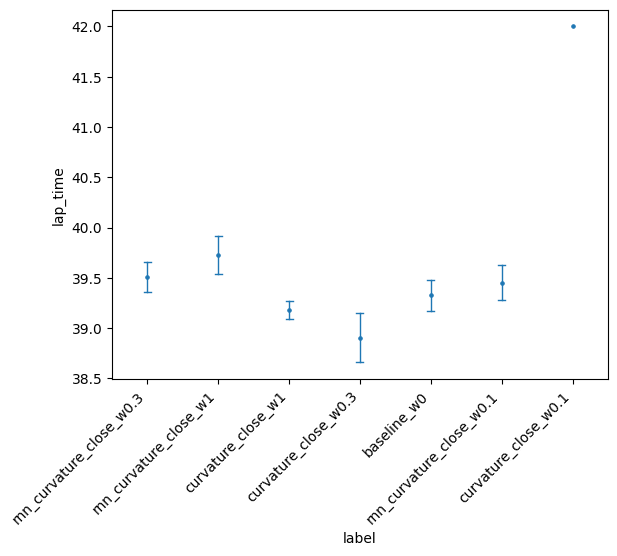

In [116]:
to_show = stats[stats["reason"] == "finished"].copy()

to_show["label"] = to_show["model_category"] + "_" + to_show["aux_weight"]


sns.pointplot(
    data=to_show,
    x="label",
    y="lap_time",
    estimator="mean",
    errorbar="se",
    capsize=0.1,
    linestyle="none",
    lw=1
)

plt.xticks(rotation=45, ha="right")

<Axes: xlabel='model_category', ylabel='lap_time'>

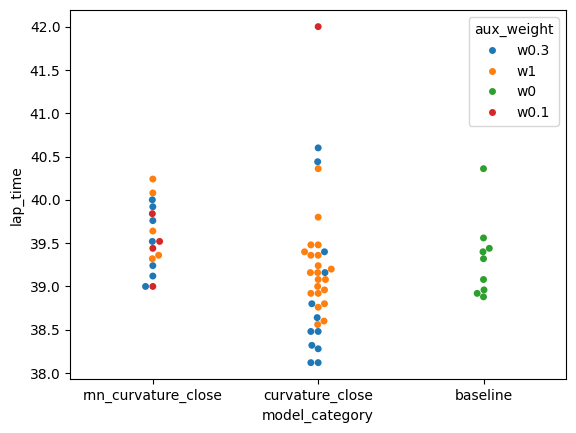

In [99]:
sns.swarmplot(stats[stats["reason"] == "finished"], x="model_category", y="lap_time", hue="aux_weight")

In [ ]:
stats[(stats["reason"] == "finished") & (stats["aux_weight"])]["lap_time"]

0      39.92
1      40.24
6      39.76
9      39.08
12     39.52
14     38.64
18     39.24
23     39.44
25     38.28
26     40.60
28     38.88
35     38.48
36     39.64
37     39.08
46     38.32
49     39.40
53     39.80
54     39.48
55     40.36
64     38.80
66     38.96
70     39.12
76     39.36
79     39.00
81     38.60
82     38.76
84     39.32
87     39.36
89     39.16
92     38.92
94     39.00
96     39.48
102    40.08
105    39.08
107    38.12
111    38.96
116    39.32
117    38.56
119    39.16
120    38.12
121    39.44
122    40.44
123    38.80
125    39.40
129    38.92
130    38.92
137    39.52
143    40.00
146    39.84
154    39.24
156    40.36
163    39.20
164    39.00
171    39.36
173    39.56
176    38.48
177    42.00
181    39.40
184    39.16
Name: lap_time, dtype: float64

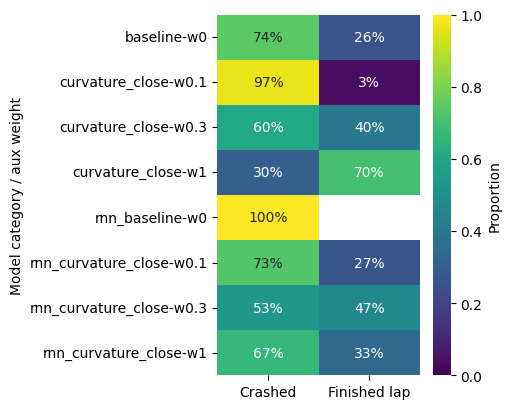

In [100]:
props = (
    stats.groupby(["model_category", "aux_weight"])["reason"]
         .value_counts(normalize=True)
         .rename("proportion")
         .reset_index()
)
props["reason"] = props["reason"].map({"done": "Crashed", "finished": "Finished lap"})

pivot = props.pivot(index=["model_category", "aux_weight"],
                    columns="reason", values="proportion")

fig, ax = plt.subplots(figsize=(5, 0.4 * len(pivot) + 1))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="viridis",
            vmin=0, vmax=1, cbar_kws={"label": "Proportion"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Model category / aux weight")
plt.tight_layout()
plt.show()

(np.float64(-28.05179786682129),
 np.float64(32.919389724731445),
 np.float64(-40.15224418640137),
 np.float64(28.86655387878418))

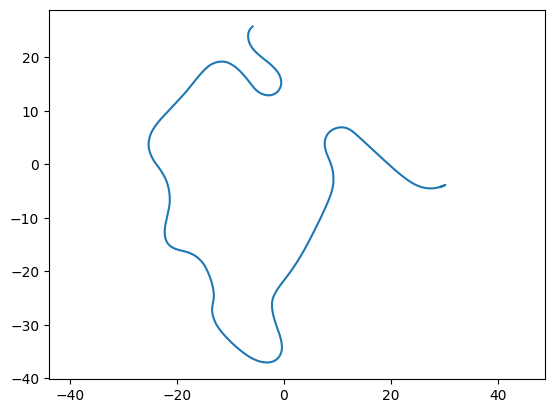

In [ ]:
traj, reason = first_laps[1]
plt.plot(traj["agents", "x"].reshape(-1), traj["agents", "z"].reshape(-1))
plt.axis("equal")

In [41]:
centerline_steps = [[-5.84774494, 25.729351], [-6.97774506, 23.0793514], [-0.51774466, 16.3993511], [-0.0690417886, 14.1375542], [-2.71774459, 12.59935], [-10.017745, 19.4993515], [-12.2777452, 19.8993511], [-18.1977444, 13.6293507], [-25.9777431, 4.03935051], [-21.6977444, -3.57064939], [-21.7277431, -8.5906496], [-22.5477448, -15.0506496], [-15.8977442, -17.1806488], [-13.1377449, -26.1206493], [-14.1377449, -28.1106491], [-5.32774496, -37.1206474], [-1.61774468, -37.5106506], [-0.197744638, -35.8206482], [-2.33774471, -25.8706493], [-1.81774473, -23.7206497], [1.34225535, -20.2406483], [9.69225502, -3.93064928], [9.80225468, -1.62064946], [8.13225555, 1.93935049], [7.30225515, 5.16935062], [10.3222551, 7.20935106], [26.110014, -5.01169348], [31.2660904, -3.52334118], [18.4722557, 8.76935005], [-2.51774454, 25.8493519]]
centerline_spline = splines.CatmullRom(centerline_steps, endconditions='closed', alpha=0.5)
centerline = centerline_spline.evaluate(np.linspace(centerline_spline.grid[0], centerline_spline.grid[-1], 1000))
po = pyclipr.ClipperOffset()
po.addPath(centerline, pyclipr.JoinType.Miter, pyclipr.EndType.Joined)
clip_outset, clip_inset = po.execute(1)

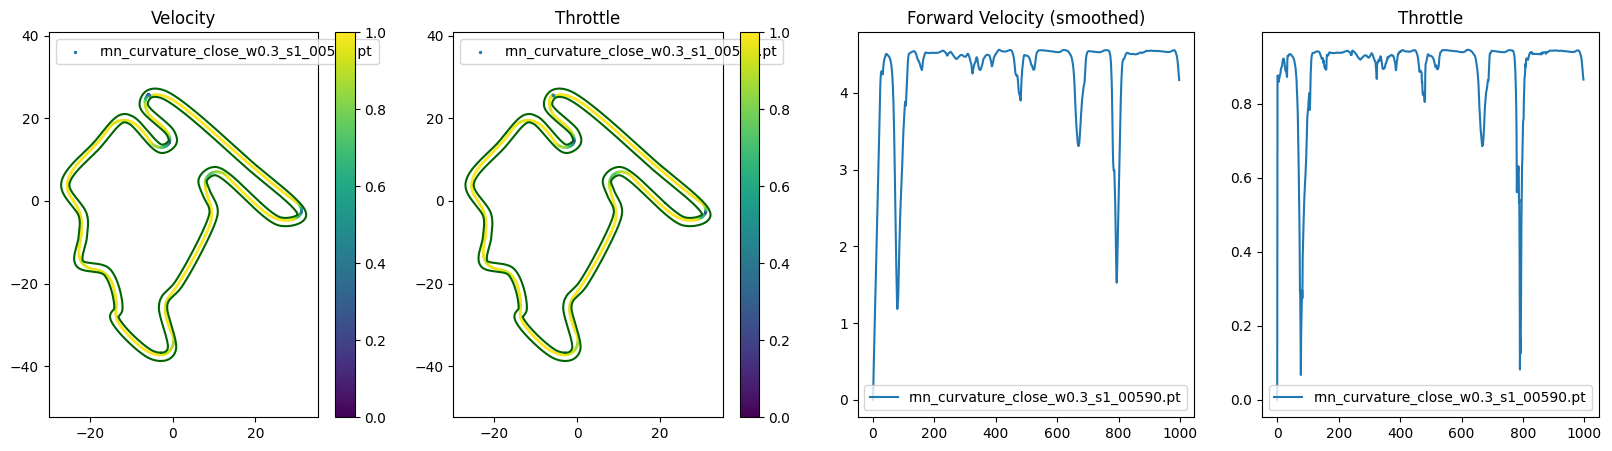

In [44]:
fig, axs = plt.subplots(1, 4,figsize=(20, 5))

axs[0].plot(clip_outset[:, 0], clip_outset[:, 1], color="darkgreen")
axs[0].plot(clip_inset[:, 0], clip_inset[:, 1], color="darkgreen")
axs[1].plot(clip_outset[:, 0], clip_outset[:, 1], color="darkgreen")
axs[1].plot(clip_inset[:, 0], clip_inset[:, 1], color="darkgreen")

lap_no = 2

for (episode, reason), model, idx in zip(first_laps[:1], MODELS, range(len(MODELS))):
    x = episode["agents", "x"].squeeze(-1)
    z = episode["agents", "z"].squeeze(-1)

    start_x, start_z = x[0], z[0]
    dist_from_start = ((x - start_x) ** 2 + (z - start_z) ** 2).numpy()


    lap_shown = episode
    
    axs[0].scatter(
        lap_shown["agents", "x"], 
        lap_shown["agents", "z"], 
        c=lap_shown["agents", "velocity_forward"],
        s=1)

    sc = axs[0].scatter(
            lap_shown["agents", "x"][0], 
            lap_shown["agents", "z"][0], 
            label=f"{model}",
            s=2
        )
    if idx == 0:
        plt.colorbar(sc)
    axs[0].legend(loc="upper left")

    axs[0].axis("equal")
    axs[0].set_title("Velocity")

    axs[1].scatter(
        lap_shown["agents", "x"], 
        lap_shown["agents", "z"], 
        c=lap_shown["agents", "throttle"],
        s=1)

    sc = axs[1].scatter(
            lap_shown["agents", "x"][0], 
            lap_shown["agents", "z"][0], 
            label=f"{model}",
            s=2
        )
    if idx == 0:
        plt.colorbar(sc)
    axs[1].legend(loc="upper left")

    axs[1].axis("equal")
    axs[1].set_title("Throttle")

    axs[2].plot(np.convolve(lap_shown["agents", "velocity_forward"].numpy().reshape(-1), np.ones(1)/1, mode="valid"), label=model)
    axs[2].set_title("Forward Velocity (smoothed)")
    axs[2].legend()

    axs[3].plot(lap_shown["agents", "throttle"].numpy().reshape(-1), label=model)
    axs[3].set_title("Throttle")
    axs[3].legend()
